# Random Forest — Riesgo cardiovascular (BRFSS 2024)

Este cuaderno implementa el modelo Random Forest dentro del protocolo experimental descrito en la Sección IV del artículo, con la misma estructura que `03_xgboost.ipynb` para que los resultados de ambos modelos sean comparables directamente:

1. Baselines (trivial y regresión logística simple).
2. Prueba del procedimiento sobre el pliegue 0.
3. Ajuste de hiperparámetros con una partición interna (sin tocar ningún pliegue de prueba).
4. Curva de aprendizaje y diagnóstico de sobreajuste.
5. Validación cruzada de 5 pliegues, con métricas de discriminación y de equidad (`pipeline.evaluar()`).
6. Comparación contra los tres puntos de referencia (baseline trivial, baseline razonable y baseline de literatura) y contra XGBoost.
7. Explicabilidad: importancia de variables (MDI y permutación) y SHAP.
8. Análisis de errores (falsos positivos, falsos negativos y casos límite).
9. Comparación exploratoria SMOTENC vs. *class weighting*.

Los datos de entrada ya vienen imputados, normalizados y balanceados con SMOTENC, generados una sola vez por `scripts/preprocesar_pliegues.py` (ver `README` del proyecto). Si la carpeta `data_procesada/` no existe, es necesario correr ese script antes de continuar.

In [1]:
import gc
import os
import sys
import time

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

from scripts import pipeline as pl

DATA_DIR = "../data_procesada"
RESULTS_DIR = "../results"
FIG_DIR = "../results/figuras_random_forest"
DATASET_PATH = "../Dataset/brfss_2024_cvd_fairness_clean.csv"
N_PLIEGUES = 5
N_JOBS = -1  # todos los nucleos disponibles

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
np.random.seed(pl.RANDOM_STATE)


def cargar(nombre):
    # Lee una particion ya preprocesada (generada por scripts/preprocesar_pliegues.py).
    tabla = pd.read_parquet(f"{DATA_DIR}/{nombre}")
    X = tabla.drop(columns=[pl.TARGET_COL])
    y = tabla[pl.TARGET_COL]
    return X, y


def metricas_umbral(y_true, y_pred, y_proba):
    # Metricas complementarias al AUROC: sensibles al desbalance (AUPRC) y al umbral (precision/recall/F1),
    # mas el Brier score como medida global de la calidad de las probabilidades.
    return {
        "auprc": average_precision_score(y_true, y_proba),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "brier": brier_score_loss(y_true, y_proba),
    }


def guardar_figura(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}", dpi=150, bbox_inches="tight")

### Entrenamiento por bloques (restricción de memoria)

Un Random Forest de 300 árboles sin límite de profundidad sobre ~634 000 registros ocupa ≈3.9 GB en memoria (≈13 MB por árbol, medido sobre el pliegue 0), más de lo disponible en la máquina donde se ejecutó este cuaderno. Para poder explorar el mismo *grid* sin recortarlo, el bosque se entrena **por bloques** de 25 árboles: cada bloque se entrena, se usa para predecir y se descarta antes de entrenar el siguiente.

Esto es matemáticamente equivalente a un único `RandomForestClassifier` con el total de árboles, porque los árboles de un Random Forest son independientes entre sí y su predicción es el **promedio** de las probabilidades de cada árbol. Lo mismo vale para las otras cantidades que se usan más adelante: la importancia MDI del bosque es el promedio de la de sus árboles, y los valores SHAP del bosque son el promedio de los de sus árboles (SHAP es aditivo). Por eso, todas se acumulan como promedios ponderados por el número de árboles de cada bloque. Cada bloque usa la semilla `RANDOM_STATE + k` (k = número de bloque), así que el resultado es reproducible. La clase predicha es `proba > 0.5`, igual que `predict()` de scikit-learn.

In [2]:
TAMANO_BLOQUE = 25


def bosque_por_bloques(params, X, y, conjuntos, al_bloque=None, tamano_bloque=TAMANO_BLOQUE):
    # Entrena un Random Forest de params["n_estimators"] arboles en bloques y devuelve, para cada
    # conjunto de `conjuntos` (dict nombre -> X), la probabilidad promedio de la clase 1.
    # `al_bloque(bloque, n_arboles)` permite acumular otras cantidades (MDI, SHAP, ...) por bloque.
    params = dict(params)
    n_total = params.pop("n_estimators")
    sumas = {nombre: np.zeros(len(Xc)) for nombre, Xc in conjuntos.items()}
    for k, inicio_bloque in enumerate(range(0, n_total, tamano_bloque)):
        n = min(tamano_bloque, n_total - inicio_bloque)
        bloque = RandomForestClassifier(**params, n_estimators=n, n_jobs=N_JOBS, random_state=pl.RANDOM_STATE + k)
        bloque.fit(X, y)
        for nombre, Xc in conjuntos.items():
            sumas[nombre] += bloque.predict_proba(Xc)[:, 1] * n
        if al_bloque is not None:
            al_bloque(bloque, n)
        del bloque
        gc.collect()
    return {nombre: s / n_total for nombre, s in sumas.items()}

In [3]:
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        "No se encontro data_procesada/. Corre primero 'python scripts/preprocesar_pliegues.py' "
        "desde la raiz del proyecto (tarda unos 15 minutos, se corre una sola vez por maquina)."
    )

print("cache encontrado en", DATA_DIR)

cache encontrado en ../data_procesada


## Baselines

Antes de entrenar el modelo principal se evalúan dos modelos de referencia bajo los mismos 5 pliegues:

- **Baseline trivial** (`DummyClassifier(strategy="stratified")`): predice al azar respetando la prevalencia real del train (≈11.8 % positivos). Se entrena con el train **sin** SMOTENC, porque sobre el train balanceado la "prevalencia" sería artificialmente 50 %. Responde a la pregunta *¿el modelo aprende algo?*; su AUROC esperado es 0.5.
- **Baseline razonable** (`LogisticRegression` con parámetros por defecto, sin ajuste de hiperparámetros ni ingeniería de variables): se entrena con el mismo train balanceado con SMOTENC que el Random Forest. Responde a *¿vale la pena la complejidad de un ensamble?*. No reemplaza el cuaderno de Regresión Logística (que ajusta hiperparámetros); es solo la referencia mínima. Con `max_iter=1000`, `lbfgs` puede no llegar a converger del todo en algunos pliegues (las variables categóricas no están escaladas); se deja así a propósito, porque el baseline debe ser el modelo simple sin ajuste.

El tercer punto de referencia es el baseline de literatura de la Sección III del artículo: AUROC entre 0.751 y 0.771, y EOD por sexo entre 0.131 y 0.136.

In [4]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# la LR por defecto (lbfgs, max_iter=1000) puede no converger del todo: es intencional, es el baseline sin ajuste
warnings.filterwarnings("ignore", category=ConvergenceWarning)

resultados_baseline = []

for i in range(N_PLIEGUES):
    X_train, y_train = cargar(f"fold_{i}_train.parquet")
    X_train_real, y_train_real = cargar(f"fold_{i}_train_sin_smotenc.parquet")
    X_test, y_test = cargar(f"fold_{i}_test.parquet")
    prot_test = X_test[pl.PROTECTED_COLS]

    candidatos = {
        "baseline_trivial": (DummyClassifier(strategy="stratified", random_state=pl.RANDOM_STATE), X_train_real, y_train_real),
        "baseline_lr": (LogisticRegression(max_iter=1000, random_state=pl.RANDOM_STATE), X_train, y_train),
    }
    for nombre, (modelo_base, X_fit, y_fit) in candidatos.items():
        modelo_base.fit(X_fit, y_fit)
        y_pred = modelo_base.predict(X_test)
        y_proba = modelo_base.predict_proba(X_test)[:, 1]
        resumen, _ = pl.evaluar(y_test, y_pred, y_proba, prot_test)
        resumen.update(metricas_umbral(y_test, y_pred, y_proba))
        resumen["modelo"] = nombre
        resumen["pliegue"] = i
        resultados_baseline.append(resumen)

    print(f"pliegue {i} listo")

tabla_baselines = pd.DataFrame(resultados_baseline)
tabla_baselines.groupby("modelo").mean(numeric_only=True).drop(columns="pliegue").round(4).T

pliegue 0 listo


pliegue 1 listo


pliegue 2 listo


pliegue 3 listo


pliegue 4 listo


modelo,baseline_lr,baseline_trivial
auroc,0.7862,0.5000
eod_sexo,0.1071,0.0038
fpr_disp_sexo,0.0447,0.0022
calib_desv_sexo,2.2983,0.1466
eod_raza,0.5953,0.0768
fpr_disp_raza,0.2993,0.0296
calib_desv_raza,2.6673,1.7151
eod_ingreso,0.2464,0.0262
fpr_disp_ingreso,0.2623,0.0120
calib_desv_ingreso,2.9380,0.7376


## Prueba sobre el pliegue 0

Antes de ejecutar el ciclo completo se valida el procedimiento sobre un único pliegue, con parámetros por defecto de scikit-learn (100 árboles, sin límite de profundidad, `max_features="sqrt"`), para confirmar que el modelo entrena correctamente, medir su costo (tiempo y tamaño de los árboles) y verificar que `pipeline.evaluar()` procesa sus predicciones sin errores.

In [5]:
X_train, y_train = cargar("fold_0_train.parquet")
X_test, y_test = cargar("fold_0_test.parquet")
prot_test = X_test[pl.PROTECTED_COLS]

print("train:", X_train.shape, "| balance:", y_train.value_counts().to_dict())
print("test: ", X_test.shape, "| balance:", y_test.value_counts().to_dict())

train: (634536, 30) | balance: {0: 317268, 1: 317268}
test:  (89952, 30) | balance: {0: 79317, 1: 10635}


### Tratamiento de variables categóricas

Igual que en XGBoost, las variables categóricas (`_RACE`, `_INCOMG1`, etc.) se mantienen con su codificación numérica original, sin *one-hot*. Para un Random Forest esto es razonable: los árboles particionan por umbrales y pueden aislar una categoría con varios cortes sucesivos, y evitar el *one-hot* mantiene las 30 columnas idénticas para los cuatro modelos, que es la condición de comparación del estudio.

In [6]:
nodos, profundidades = [], []


def registrar_tamano(bloque, n):
    nodos.extend(arbol.tree_.node_count for arbol in bloque.estimators_)
    profundidades.extend(arbol.tree_.max_depth for arbol in bloque.estimators_)


inicio = time.time()
y_proba = bosque_por_bloques(dict(n_estimators=100), X_train, y_train, {"test": X_test}, al_bloque=registrar_tamano)["test"]
y_pred = (y_proba > 0.5).astype(int)
tiempo_fit = time.time() - inicio

nodos, profundidades = np.array(nodos), np.array(profundidades)
print(f"entrenamiento + prediccion: {tiempo_fit:.0f}s")
print(f"nodos por arbol: media {nodos.mean():,.0f} | profundidad media {profundidades.mean():.1f} (max {profundidades.max()})")

entrenamiento + prediccion: 102s
nodos por arbol: media 162,431 | profundidad media 59.5 (max 73)


In [7]:
resumen, detalle = pl.evaluar(y_test, y_pred, y_proba, prot_test)

print("RESUMEN (pliegue 0, parametros por defecto):")
for k, v in resumen.items():
    print(f"  {k}: {v:.4f}")

detalle["_RACE"]

RESUMEN (pliegue 0, parametros por defecto):
  auroc: 0.7932
  eod_sexo: 0.1034
  fpr_disp_sexo: 0.0363
  calib_desv_sexo: 1.1098
  eod_raza: 0.3738
  fpr_disp_raza: 0.1108
  calib_desv_raza: 1.2364
  eod_ingreso: 0.2739
  fpr_disp_ingreso: 0.1141
  calib_desv_ingreso: 1.2106


,grupo,n,tpr,fpr,calibracion
0,1.0,66555,0.400326,0.114654,1.998229
1,2.0,6987,0.100391,0.026045,1.617366
2,4.0,2469,0.026549,0.003820,1.887168
3,7.0,2053,0.072581,0.012188,1.267540
4,8.0,9544,0.111481,0.012636,2.236406
5,6.0,701,0.122222,0.008183,1.328000
6,3.0,1248,0.128655,0.016713,1.276550
7,5.0,395,0.063830,0.017241,1.182979


## Ajuste de hiperparámetros

Se realiza una búsqueda en *grid* sobre los tres hiperparámetros que más controlan la complejidad de un Random Forest:

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| `n_estimators` | 100, 300 | Más árboles reducen la varianza del ensamble hasta estabilizarse; 300 permite ver si la ganancia sobre 100 justifica el triple de costo. Son los mismos valores explorados en XGBoost. |
| `max_depth` | 10, 20, `None` | Controla el sobreajuste de cada árbol. `None` (árboles completos) es el valor por defecto de Breiman; 10 y 20 restringen la complejidad, y además reducen mucho el tamaño en memoria del modelo. |
| `min_samples_leaf` | 1, 5 | Suaviza las hojas: con 1 cada hoja puede memorizar un solo registro (incluidos los sintéticos de SMOTENC); con 5 se exige más evidencia por hoja. |

`max_features` se fija en `"sqrt"` (≈5 de 30 variables por división), el valor recomendado para clasificación. En total son 12 combinaciones (2 400 árboles), el costo computacional que se asume para esta búsqueda.

Igual que en XGBoost, para no comprometer los datos de prueba de ningún pliegue, la búsqueda se hace sobre la partición interna generada por `scripts/preprocesar_pliegues.py` a partir del train del pliegue 0 (80 % entrenamiento interno con SMOTENC / 20 % validación interna sin SMOTENC). Los 5 pliegues oficiales permanecen intactos durante todo este proceso.

In [8]:
X_tr_int, y_tr_int = cargar("tuning_train_interno.parquet")
X_val_int, y_val_int = cargar("tuning_validacion_interna.parquet")

print("train interno:", X_tr_int.shape, "| validacion interna:", X_val_int.shape)

train interno: (507628, 30) | validacion interna: (71962, 30)


In [9]:
grid = [
    dict(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
    for n_estimators in [100, 300]
    for max_depth in [10, 20, None]
    for min_samples_leaf in [1, 5]
]

resultados_grid = []
for params in grid:
    inicio = time.time()
    proba_val = bosque_por_bloques({**params, "max_features": "sqrt"}, X_tr_int, y_tr_int, {"val": X_val_int})["val"]
    duracion = time.time() - inicio
    resultados_grid.append({**params, "auroc_validacion": roc_auc_score(y_val_int, proba_val), "segundos": round(duracion)})
    print(params, f"AUROC={resultados_grid[-1]['auroc_validacion']:.4f} ({duracion:.0f}s)")

tabla_grid = pd.DataFrame(resultados_grid)
tabla_grid["max_depth"] = tabla_grid["max_depth"].astype(object).where(tabla_grid["max_depth"].notna(), "None")
tabla_grid = tabla_grid.sort_values("auroc_validacion", ascending=False)
tabla_grid.to_csv(f"{RESULTS_DIR}/grid_random_forest.csv", index=False)
tabla_grid.round(4)

{'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 1} AUROC=0.7921 (60s)


{'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 5} AUROC=0.7924 (42s)


{'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 1} AUROC=0.7891 (55s)


{'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 5} AUROC=0.7895 (47s)


{'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1} AUROC=0.7956 (49s)


{'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 5} AUROC=0.7961 (43s)


... (3 outputs left out)

{'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 5} AUROC=0.7908 (118s)


{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1} AUROC=0.7982 (138s)


{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5} AUROC=0.7973 (211s)


,n_estimators,max_depth,min_samples_leaf,auroc_validacion,segundos
10,300,None,1,0.7982,138
11,300,None,5,0.7973,211
5,100,None,5,0.7961,43
4,100,None,1,0.7956,49
7,300,10.0,5,0.7926,74
1,100,10.0,5,0.7924,42
6,300,10.0,1,0.7921,74
0,100,10.0,1,0.7921,60
9,300,20.0,5,0.7908,118
8,300,20.0,1,0.7906,119


In [10]:
mejor = tabla_grid.iloc[0]
MEJORES_HIPERPARAMETROS = dict(
    n_estimators=int(mejor["n_estimators"]),
    max_depth=None if mejor["max_depth"] == "None" else int(mejor["max_depth"]),
    min_samples_leaf=int(mejor["min_samples_leaf"]),
    max_features="sqrt",
)
MEJORES_HIPERPARAMETROS

{'n_estimators': 300,
 'max_depth': None,
 'min_samples_leaf': 1,
 'max_features': 'sqrt'}

**Resultado de la búsqueda.** La mejor combinación es `n_estimators=300, max_depth=None, min_samples_leaf=1` (AUROC de validación 0.7982), es decir, árboles completos, que es la configuración por defecto de Breiman y de scikit-learn. Observaciones:

- **La profundidad es el hiperparámetro que más pesa**: los árboles sin límite (0.796–0.798) superan a `max_depth=10` (≈0.792) y a `max_depth=20` (≈0.790). La relación no es monótona: profundidad 20 queda por debajo de 10. Una explicación plausible es que a profundidad 20 los árboles ya empiezan a ajustarse a la región sintética de SMOTENC sin llegar a hojas puras, mientras que los árboles completos, aunque memorizan, se compensan entre sí al promediar; en todo caso la diferencia es pequeña (≤0.008).
- **`min_samples_leaf` casi no influye** (diferencias ≤0.001), y **300 árboles mejoran poco sobre 100** (entre +0.000 y +0.003), a costa de ~3 veces el tiempo.
- Frente a XGBoost en la misma partición de validación (0.8064), el Random Forest queda ≈0.008 por debajo.
- Costo de la búsqueda: ≈17 minutos para las 12 combinaciones (2 400 árboles) en un portátil de 12 hilos, con entrenamiento por bloques.

## Curva de aprendizaje y diagnóstico de sobreajuste

Se entrena el modelo con los hiperparámetros elegidos sobre fracciones crecientes del train interno (5 % a 100 %) y se mide el AUROC tanto en el propio subconjunto de entrenamiento como en la validación interna. La curva responde dos preguntas: si el modelo sobreajusta (brecha grande entre ambas curvas) y si más datos ayudarían (curva de validación todavía en ascenso al 100 %).

Igual que en la búsqueda de hiperparámetros, se usa solo la partición interna, no los pliegues de prueba. Nota: el AUROC de entrenamiento se calcula sobre datos que incluyen registros sintéticos de SMOTENC.

  5% (25,381 filas): train=1.0000 | validacion=0.7930


 10% (50,762 filas): train=1.0000 | validacion=0.7891


 25% (126,907 filas): train=1.0000 | validacion=0.7934


 50% (253,814 filas): train=1.0000 | validacion=0.7941


100% (507,628 filas): train=1.0000 | validacion=0.7979


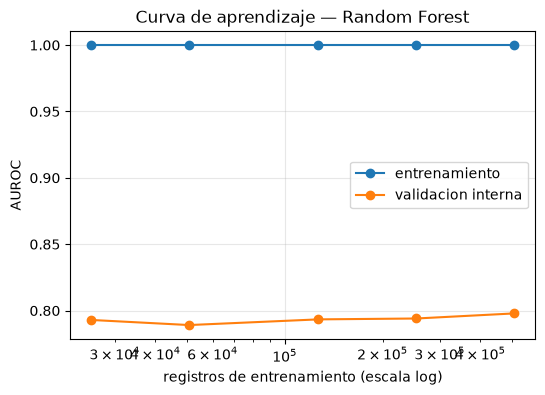

,fraccion,n_train,auroc_train,auroc_validacion
0,0.05,25381,1.0,0.7930
1,0.10,50762,1.0,0.7891
2,0.25,126907,1.0,0.7934
3,0.50,253814,1.0,0.7941
4,1.00,507628,1.0,0.7979


In [11]:
fracciones = [0.05, 0.10, 0.25, 0.50, 1.00]
curva = []
rng = np.random.default_rng(pl.RANDOM_STATE)

for fraccion in fracciones:
    n = int(len(X_tr_int) * fraccion)
    idx = rng.choice(len(X_tr_int), size=n, replace=False)
    X_sub, y_sub = X_tr_int.iloc[idx], y_tr_int.iloc[idx]

    # AUROC de entrenamiento sobre una muestra de hasta 50k filas (predecir todo el train es costoso y no cambia la conclusion)
    idx_eval = rng.choice(n, size=min(n, 50_000), replace=False)
    probas = bosque_por_bloques(MEJORES_HIPERPARAMETROS, X_sub, y_sub,
                                {"train": X_sub.iloc[idx_eval], "val": X_val_int})
    auroc_train = roc_auc_score(y_sub.iloc[idx_eval], probas["train"])
    auroc_val = roc_auc_score(y_val_int, probas["val"])
    curva.append({"fraccion": fraccion, "n_train": n, "auroc_train": auroc_train, "auroc_validacion": auroc_val})
    print(f"{fraccion:>4.0%} ({n:,} filas): train={auroc_train:.4f} | validacion={auroc_val:.4f}")

tabla_curva = pd.DataFrame(curva)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(tabla_curva["n_train"], tabla_curva["auroc_train"], "o-", label="entrenamiento")
ax.plot(tabla_curva["n_train"], tabla_curva["auroc_validacion"], "o-", label="validacion interna")
ax.set_xscale("log")
ax.set_xlabel("registros de entrenamiento (escala log)")
ax.set_ylabel("AUROC")
ax.set_title("Curva de aprendizaje — Random Forest")
ax.grid(alpha=0.3)
ax.legend()
guardar_figura(fig, "curva_aprendizaje.png")
plt.show()
tabla_curva.round(4)

**Diagnóstico.** El AUROC de entrenamiento es 1.000 en todas las fracciones: con árboles completos y `min_samples_leaf=1`, cada árbol memoriza su muestra *bootstrap*, así que el ensamble reproduce perfectamente el train. Esa brecha (≈0.20) es **sobreajuste en sentido estricto**, pero es el comportamiento esperado de un Random Forest y no implica que generalice mal: el AUROC de validación (0.793–0.798) es el mejor del *grid*, mejor que el de los modelos más restringidos (`max_depth=10`, que sobreajusta menos pero discrimina peor). En un Random Forest el control de la varianza lo hace el promedio entre árboles, no la poda de cada árbol.

La curva de validación sube poco con más datos (de 0.793 con el 5 % a 0.798 con el 100 %, con una caída puntual al 10 %): el modelo está **cerca de su techo con estas variables**. Más registros no cambiarían de forma relevante el resultado; para mejorar haría falta mejor información (variables más predictivas o menos ruidosas), no más volumen. No hay señales de subajuste: el modelo supera claramente al baseline trivial y al de regresión logística.

In [12]:
del X_tr_int, y_tr_int, X_val_int, y_val_int
gc.collect();

## Ciclo completo de validación cruzada (5 pliegues)

Se repite el procedimiento de forma independiente para cada uno de los 5 pliegues, con los hiperparámetros elegidos, y se reporta el promedio y la desviación estándar de cada métrica entre pliegues (Sección IV-F del artículo). Cada pliegue de prueba se usa una única vez, aquí.

Además de las métricas de `pipeline.evaluar()`, se guardan las predicciones de cada pliegue de prueba (*out-of-fold*): como cada registro del dataset aparece en exactamente un pliegue de prueba, juntas cubren todo el dataset y se usan después para las curvas ROC/PR y el análisis de errores. También se calcula el AUROC sobre el train real (sin registros sintéticos) de cada pliegue para el diagnóstico de sobreajuste.

En el último pliegue (pliegue 4) se aprovecha el mismo entrenamiento por bloques para acumular las cantidades de la sección de explicabilidad (importancia MDI, importancia por permutación y SHAP) sobre su pliegue de prueba, sin tener que volver a entrenar el modelo. La celda siguiente prepara esas muestras y el acumulador.

In [13]:
import shap

N_SHAP_EXACTO = 300     # registros para TreeSHAP exacto (sobre un bloque de 25 arboles, ver explicabilidad)
N_SHAP_APROX = 2000     # registros para SHAP aproximado (Saabas) sobre todos los arboles
N_PERMUTACION = 20_000  # registros para la importancia por permutacion
N_REPETICIONES = 3


class AcumuladorXAI:
    # Acumula, bloque por bloque, MDI, SHAP y probabilidades con variables permutadas.
    def __init__(self, X_test, y_test):
        self.X_shap_exacto = X_test.sample(n=N_SHAP_EXACTO, random_state=pl.RANDOM_STATE)
        self.X_shap_aprox = X_test.sample(n=N_SHAP_APROX, random_state=pl.RANDOM_STATE + 1)
        self.X_perm = X_test.sample(n=N_PERMUTACION, random_state=pl.RANDOM_STATE + 2)
        self.y_perm = y_test.loc[self.X_perm.index]
        rng = np.random.default_rng(pl.RANDOM_STATE)
        self.permutaciones = {(col, r): rng.permutation(N_PERMUTACION)
                              for col in X_test.columns for r in range(N_REPETICIONES)}
        self.columnas = list(X_test.columns)
        self.n_total = 0
        self.mdi = np.zeros(len(self.columnas))
        self.shap_aprox = np.zeros((N_SHAP_APROX, len(self.columnas)))
        self.proba_perm_base = np.zeros(N_PERMUTACION)
        self.proba_perm = {clave: np.zeros(N_PERMUTACION) for clave in self.permutaciones}
        self.shap_exacto = None
        self.segundos_shap_exacto = None

    @staticmethod
    def _clase_positiva(valores):
        # segun la version de shap: lista [clase0, clase1] o arreglo (n, variables, clases)
        if isinstance(valores, list):
            return valores[1]
        return valores[..., 1] if valores.ndim == 3 else valores

    def __call__(self, bloque, n):
        explicador = shap.TreeExplainer(bloque)
        if self.shap_exacto is None:  # TreeSHAP exacto solo con el primer bloque (costoso en arboles profundos)
            inicio = time.time()
            self.shap_exacto = self._clase_positiva(explicador.shap_values(self.X_shap_exacto, check_additivity=False))
            self.segundos_shap_exacto = time.time() - inicio
        self.shap_aprox += self._clase_positiva(
            explicador.shap_values(self.X_shap_aprox, approximate=True, check_additivity=False)) * n
        self.mdi += bloque.feature_importances_ * n
        self.proba_perm_base += bloque.predict_proba(self.X_perm)[:, 1] * n
        valores_originales = self.X_perm.to_numpy()
        for (col, r), orden in self.permutaciones.items():
            j = self.columnas.index(col)
            X_p = valores_originales.copy()
            X_p[:, j] = valores_originales[orden, j]
            self.proba_perm[(col, r)] += bloque.predict_proba(pd.DataFrame(X_p, columns=self.columnas))[:, 1] * n
        self.n_total += n

C:\Proyectos\GitHub\PrediccionCardio-RF-local\.venv\Lib\site-packages\shap\plots\colors\_colors.py:47: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  red_blue.set_bad(gray_rgb.tolist(), 1.0)
C:\Proyectos\GitHub\PrediccionCardio-RF-local\.venv\Lib\site-packages\shap\plots\colors\_colors.py:48: PendingDeprecationWarning: The set_over function will be deprecated in a future version. Use cmap.with_extremes(over=...) or Colormap(over=...) instead.
  red_blue.set_over(gray_rgb.tolist(), 1.0)
C:\Proyectos\GitHub\PrediccionCardio-RF-local\.venv\Lib\site-packages\shap\plots\colors\_colors.py:49: PendingDeprecationWarning: The set_under function will be deprecated in a future version. Use cmap.with_extremes(under=...) or Colormap(under=...) instead.
  red_blue.set_under(gray_rgb.tolist(), 1.0)  # "under" is incorrectly used instead of "bad" in the scatter plot


In [14]:
resultados = []
detalle_total = []
extras = []
predicciones_oof = []

for i in range(N_PLIEGUES):
    inicio = time.time()
    X_train, y_train = cargar(f"fold_{i}_train.parquet")
    X_test, y_test = cargar(f"fold_{i}_test.parquet")
    X_train_real, y_train_real = cargar(f"fold_{i}_train_sin_smotenc.parquet")
    prot_test = X_test[pl.PROTECTED_COLS]
    muestra = X_train_real.sample(n=min(50_000, len(X_train_real)), random_state=pl.RANDOM_STATE).index

    acumulador = AcumuladorXAI(X_test, y_test) if i == N_PLIEGUES - 1 else None
    probas = bosque_por_bloques(MEJORES_HIPERPARAMETROS, X_train, y_train,
                                {"test": X_test, "train_real": X_train_real.loc[muestra]}, al_bloque=acumulador)
    y_proba = probas["test"]
    y_pred = (y_proba > 0.5).astype(int)

    resumen, detalle = pl.evaluar(y_test, y_pred, y_proba, prot_test)
    resumen["modelo"] = "random_forest"
    resumen["pliegue"] = i
    resultados.append(resumen)

    for col, tabla_grupo in detalle.items():
        tabla_grupo = tabla_grupo.copy()
        tabla_grupo["atributo"] = pl.SUFIJOS_PROTEGIDAS[col]
        tabla_grupo["modelo"] = "random_forest"
        tabla_grupo["pliegue"] = i
        detalle_total.append(tabla_grupo)

    # AUROC sobre el train real del pliegue (muestra de 50k filas) para comparar contra el de prueba
    auroc_train_real = roc_auc_score(y_train_real.loc[muestra], probas["train_real"])
    del X_train_real, y_train_real, X_train, y_train

    extras.append({"pliegue": i, "auroc_train_real": auroc_train_real, **metricas_umbral(y_test, y_pred, y_proba)})
    predicciones_oof.append(pd.DataFrame({"pliegue": i, "fila_test": np.arange(len(y_test)), "y": y_test.to_numpy(),
                                          "proba": y_proba, "pred": y_pred}))

    print(f"pliegue {i} listo | AUROC test = {resumen['auroc']:.4f} | AUROC train = {auroc_train_real:.4f} ({time.time() - inicio:.0f}s)")

xai = acumulador  # acumulado sobre el pliegue 4, se usa en la seccion de explicabilidad

pliegue 0 listo | AUROC test = 0.7962 | AUROC train = 1.0000 (350s)


pliegue 1 listo | AUROC test = 0.7963 | AUROC train = 1.0000 (346s)


pliegue 2 listo | AUROC test = 0.7962 | AUROC train = 1.0000 (338s)


pliegue 3 listo | AUROC test = 0.7959 | AUROC train = 1.0000 (343s)


pliegue 4 listo | AUROC test = 0.7978 | AUROC train = 1.0000 (1796s)


In [15]:
tabla_metricas = pd.DataFrame(resultados)
columnas_ordenadas = ["modelo", "pliegue"] + [c for c in tabla_metricas.columns if c not in ("modelo", "pliegue")]
tabla_metricas = tabla_metricas[columnas_ordenadas]

resumen_cv = tabla_metricas.drop(columns=["modelo", "pliegue"]).agg(["mean", "std"]).round(4)

tabla_metricas.round(4)

,modelo,pliegue,auroc,eod_sexo,fpr_disp_sexo,calib_desv_sexo,eod_raza,fpr_disp_raza,calib_desv_raza,eod_ingreso,fpr_disp_ingreso,calib_desv_ingreso
0,random_forest,0,0.7962,0.1100,0.0364,1.1080,0.3671,0.1118,1.2329,0.2636,0.1139,1.2102
1,random_forest,1,0.7963,0.1113,0.0301,1.0592,0.3571,0.1127,1.0666,0.2855,0.1203,1.3450
2,random_forest,2,0.7962,0.1042,0.0316,1.0961,0.4056,0.1123,1.0758,0.2526,0.1102,1.3682
3,random_forest,3,0.7959,0.1011,0.0280,1.1055,0.3505,0.1146,1.2952,0.2620,0.1281,1.3287
4,random_forest,4,0.7978,0.0981,0.0322,1.1014,0.3877,0.1099,1.0297,0.2259,0.1205,1.2418


In [16]:
resumen_cv

,auroc,eod_sexo,fpr_disp_sexo,calib_desv_sexo,eod_raza,fpr_disp_raza,calib_desv_raza,eod_ingreso,fpr_disp_ingreso,calib_desv_ingreso
mean,0.7965,0.1049,0.0317,1.094,0.3736,0.1123,1.1400,0.2579,0.1186,1.2988
std,0.0008,0.0057,0.0031,0.020,0.0227,0.0017,0.1166,0.0216,0.0069,0.0688


**Resultado.** AUROC promedio **0.7965 ± 0.0008** en los 5 pliegues: muy estable entre pliegues (todos entre 0.7959 y 0.7978) y consistente con el AUROC de validación del ajuste (0.7982), lo que indica que la partición interna fue representativa y que no hubo sobreajuste a la validación. Supera el baseline de literatura (0.751–0.771), pero queda ≈0.011 por debajo de XGBoost (0.8071).

En equidad, el Random Forest es **peor que XGBoost en todas las métricas**:

| Métrica (media 5 pliegues) | Random Forest | XGBoost |
|---|---|---|
| EOD sexo / raza / ingreso | 0.105 / 0.374 / 0.258 | 0.076 / 0.201 / 0.216 |
| Disparidad de FPR sexo / raza / ingreso | 0.032 / 0.112 / 0.119 | 0.017 / 0.044 / 0.074 |
| Desviación de calibración sexo / raza / ingreso | 1.09 / 1.14 / 1.30 | 0.30 / 0.36 / 0.34 |

La disparidad más grande es por **raza** (EOD 0.37): el TPR del grupo 1 (blanca no hispana) es ≈0.40, mientras que en varios grupos minoritarios está entre 0.02 y 0.13 (ver `detalle_random_forest.csv`). Parte de esto es tamaño de muestra (el grupo 5 tiene ≈400 registros por pliegue y su TPR oscila entre 0.02 y 0.12), pero la brecha con los grupos grandes es sistemática en todos los pliegues.

La **desviación de calibración** (≈1.1–1.3: en el grupo más desviado de cada atributo, el modelo predice en total ≈2.1–2.3 veces más riesgo del que realmente ocurre) se explica porque el bosque se entrena sobre datos balanceados 50/50 por SMOTENC, mientras que la prevalencia real es 11.8 %: sus probabilidades quedan desplazadas hacia arriba. XGBoost, con la misma entrada, sobreestima mucho menos.

## Guardado de resultados

Los resultados por pliegue se guardan en `results/metrics_random_forest.csv` y el desglose por grupo demográfico en `results/detalle_random_forest.csv`, con exactamente las mismas columnas que los de XGBoost, para que el cuaderno de comparación de los cuatro modelos los pueda leer de la misma forma. Las métricas complementarias (AUPRC, precisión, recall, F1, Brier y AUROC de entrenamiento) van en un archivo aparte (`extras_random_forest.csv`) para no alterar el formato compartido.

In [17]:
tabla_metricas.to_csv(f"{RESULTS_DIR}/metrics_random_forest.csv", index=False)

tabla_detalle = pd.concat(detalle_total, ignore_index=True)
tabla_detalle = tabla_detalle[["modelo", "pliegue", "atributo", "grupo", "n", "tpr", "fpr", "calibracion"]]
tabla_detalle.to_csv(f"{RESULTS_DIR}/detalle_random_forest.csv", index=False)

tabla_extras = pd.DataFrame(extras)
tabla_extras["auroc_test"] = tabla_metricas["auroc"].to_numpy()
tabla_extras["brecha_train_test"] = tabla_extras["auroc_train_real"] - tabla_extras["auroc_test"]
tabla_extras.insert(0, "modelo", "random_forest")
tabla_extras.to_csv(f"{RESULTS_DIR}/extras_random_forest.csv", index=False)

print("guardado en results/metrics_random_forest.csv, detalle_random_forest.csv y extras_random_forest.csv")
tabla_detalle.sort_values("n").head(10)

guardado en results/metrics_random_forest.csv, detalle_random_forest.csv y extras_random_forest.csv


,modelo,pliegue,atributo,grupo,n,tpr,fpr,calibracion
9,random_forest,0,raza,5.0,395,0.063830,0.011494,1.186879
60,random_forest,3,raza,5.0,408,0.115385,0.000000,1.189551
77,random_forest,4,raza,5.0,408,0.019231,0.002809,1.226538
26,random_forest,1,raza,5.0,409,0.063492,0.002890,1.002751
43,random_forest,2,raza,5.0,433,0.055556,0.002519,1.738056
7,random_forest,0,raza,6.0,701,0.122222,0.006547,1.321519
40,random_forest,2,raza,6.0,740,0.096774,0.013910,1.391290
56,random_forest,3,raza,6.0,742,0.115385,0.012539,1.225064
72,random_forest,4,raza,6.0,758,0.087379,0.018321,1.269256
24,random_forest,1,raza,6.0,768,0.082474,0.016393,1.291890


## Métricas complementarias y diagnóstico de sobreajuste

El AUROC es la métrica principal del estudio porque no depende del umbral y es la que reporta la literatura (Sección III). Con un 11.8 % de positivos, la *accuracy* no es informativa (predecir siempre "sin riesgo" da 88 %), así que se complementa con:

- **AUPRC** (*average precision*): a diferencia del AUROC, sí se ve afectada por la prevalencia, y muestra qué tan útil es el modelo para encontrar positivos. Su referencia aleatoria es la prevalencia (≈0.118), no 0.5.
- **Precisión, recall y F1** al umbral 0.5 (el mismo que usa `pipeline.evaluar()` para TPR/FPR).
- **Brier score**: error cuadrático de las probabilidades; resume calibración y discriminación a la vez.
- **Brecha train–test** del AUROC: diagnóstico directo de sobreajuste.

In [18]:
tabla_extras.drop(columns=["modelo"]).round(4)

,pliegue,auroc_train_real,auprc,precision,recall,f1,brier,auroc_test,brecha_train_test
0,0,1.0,0.3104,0.3450,0.3443,0.3447,0.1116,0.7962,0.2038
1,1,1.0,0.3138,0.3481,0.3458,0.3470,0.1111,0.7963,0.2037
2,2,1.0,0.3107,0.3472,0.3409,0.3440,0.1110,0.7962,0.2038
3,3,1.0,0.3148,0.3444,0.3407,0.3425,0.1108,0.7959,0.2041
4,4,1.0,0.3156,0.3501,0.3445,0.3473,0.1103,0.7978,0.2022


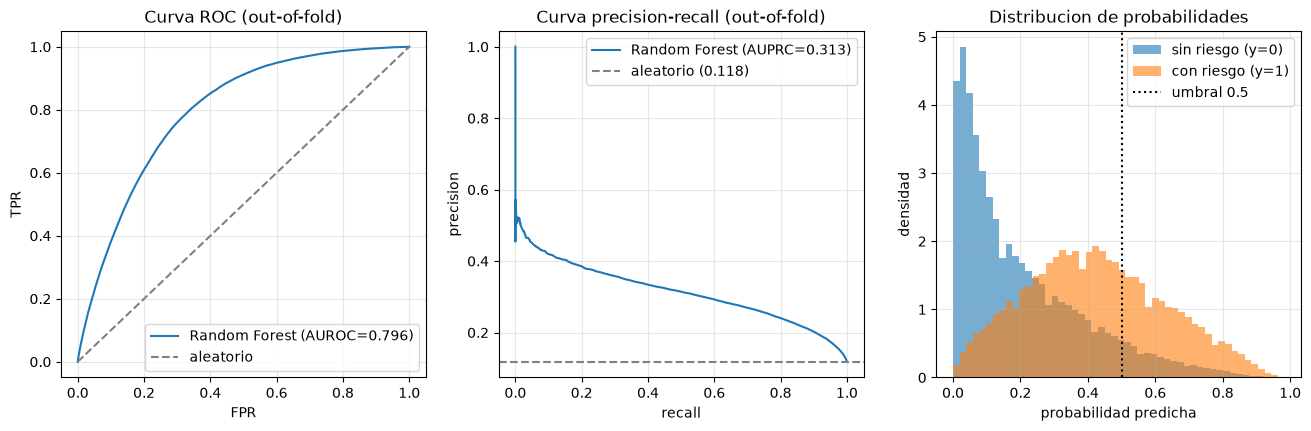

,pred: sin riesgo,pred: con riesgo
real: sin riesgo,362230,34355
real: con riesgo,34923,18252


In [19]:
oof = pd.concat(predicciones_oof, ignore_index=True)

fpr_curva, tpr_curva, _ = roc_curve(oof["y"], oof["proba"])
prec_curva, rec_curva, _ = precision_recall_curve(oof["y"], oof["proba"])
prevalencia = oof["y"].mean()

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
ejes[0].plot(fpr_curva, tpr_curva, label=f"Random Forest (AUROC={roc_auc_score(oof['y'], oof['proba']):.3f})")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="aleatorio")
ejes[0].set(xlabel="FPR", ylabel="TPR", title="Curva ROC (out-of-fold)")
ejes[0].legend(loc="lower right")

ejes[1].plot(rec_curva, prec_curva, label=f"Random Forest (AUPRC={average_precision_score(oof['y'], oof['proba']):.3f})")
ejes[1].axhline(prevalencia, ls="--", color="gray", label=f"aleatorio ({prevalencia:.3f})")
ejes[1].set(xlabel="recall", ylabel="precision", title="Curva precision-recall (out-of-fold)")
ejes[1].legend(loc="upper right")

ejes[2].hist(oof.loc[oof["y"] == 0, "proba"], bins=50, alpha=0.6, density=True, label="sin riesgo (y=0)")
ejes[2].hist(oof.loc[oof["y"] == 1, "proba"], bins=50, alpha=0.6, density=True, label="con riesgo (y=1)")
ejes[2].axvline(0.5, color="black", ls=":", label="umbral 0.5")
ejes[2].set(xlabel="probabilidad predicha", ylabel="densidad", title="Distribucion de probabilidades")
ejes[2].legend()
for eje in ejes:
    eje.grid(alpha=0.3)
guardar_figura(fig, "roc_pr_distribucion.png")
plt.show()

matriz = confusion_matrix(oof["y"], oof["pred"])
pd.DataFrame(matriz, index=["real: sin riesgo", "real: con riesgo"], columns=["pred: sin riesgo", "pred: con riesgo"])

**Métricas complementarias.** Con el umbral 0.5, el modelo tiene **precisión ≈0.35 y recall ≈0.34** (F1 ≈0.35): detecta un tercio de los casos con riesgo, y de cada tres alertas, una es correcta. El AUPRC (≈0.31) es 2.6 veces el valor aleatorio (0.118), mejora real pero modesta. El Brier score (0.111) es mejor que el de la regresión logística baseline (0.176).

La matriz de confusión *out-of-fold* (449 760 registros) muestra 18 252 VP, 34 923 FN, 34 355 FP y 362 230 VN: con el umbral 0.5 el modelo **pierde dos de cada tres positivos**. Para un uso de tamizaje, donde un falso negativo es más grave que un falso positivo, convendría un umbral más bajo; la curva precisión-recall muestra el costo en precisión de cada punto de recall adicional. El umbral se mantiene en 0.5 aquí para que las métricas de equidad (TPR/FPR por grupo) sean comparables con las de los otros tres modelos.

La brecha train–test (≈0.20 en todos los pliegues) confirma lo visto en la curva de aprendizaje: memorización total del train con generalización estable.

## Comparación contra los puntos de referencia

Se compara el Random Forest contra los tres puntos de referencia exigidos (baseline trivial, baseline de regresión logística y baseline de literatura) y, si su archivo de resultados existe, contra XGBoost. Las cifras son el promedio de los 5 pliegues (± desviación estándar en el AUROC).

In [20]:
filas = []
for nombre, tabla in tabla_baselines.groupby("modelo"):
    filas.append((nombre, tabla))
filas.append(("random_forest", tabla_metricas.merge(tabla_extras[["pliegue", "auprc", "f1", "brier"]], on="pliegue")))

ruta_xgb = f"{RESULTS_DIR}/metrics_xgboost.csv"
if os.path.exists(ruta_xgb):
    filas.append(("xgboost", pd.read_csv(ruta_xgb)))

columnas_comparacion = ["auroc", "auprc", "f1", "brier", "eod_sexo", "eod_raza", "eod_ingreso",
                        "fpr_disp_sexo", "fpr_disp_raza", "fpr_disp_ingreso"]
comparacion_refs = []
for nombre, tabla in filas:
    fila = {"modelo": nombre, "auroc_std": tabla["auroc"].std()}
    for c in columnas_comparacion:
        fila[c] = tabla[c].mean() if c in tabla.columns else np.nan
    comparacion_refs.append(fila)

comparacion_refs.append({"modelo": "literatura (Sec. III)", "auroc": 0.761, "auroc_std": np.nan, "eod_sexo": 0.1335})
tabla_comparacion = pd.DataFrame(comparacion_refs).set_index("modelo")[["auroc", "auroc_std"] + columnas_comparacion[1:]]
tabla_comparacion.round(4)

,auroc,auroc_std,auprc,f1,brier,eod_sexo,eod_raza,eod_ingreso,fpr_disp_sexo,fpr_disp_raza,fpr_disp_ingreso
modelo,,,,,,,,,,,
baseline_lr,0.7862,0.0018,0.3289,0.3790,0.1758,0.1071,0.5953,0.2464,0.0447,0.2993,0.2623
baseline_trivial,0.5000,0.0010,0.1182,0.1178,0.2077,0.0038,0.0768,0.0262,0.0022,0.0296,0.0120
random_forest,0.7965,0.0008,0.3130,0.3451,0.1110,0.1049,0.3736,0.2579,0.0317,0.1123,0.1186
xgboost,0.8071,0.0015,NaN,NaN,NaN,0.0756,0.2005,0.2158,0.0165,0.0440,0.0735
literatura (Sec. III),0.7610,NaN,NaN,NaN,NaN,0.1335,NaN,NaN,NaN,NaN,NaN


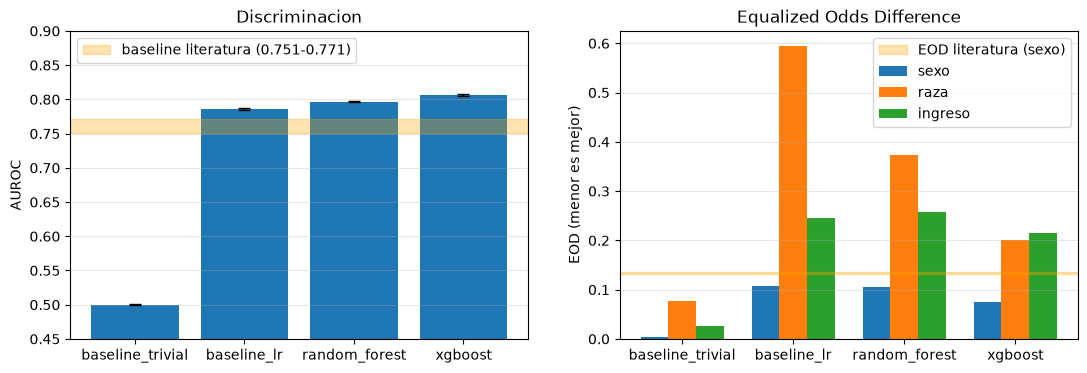

In [21]:
orden = [m for m in ["baseline_trivial", "baseline_lr", "random_forest", "xgboost"] if m in tabla_comparacion.index]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

ejes[0].bar(orden, tabla_comparacion.loc[orden, "auroc"], yerr=tabla_comparacion.loc[orden, "auroc_std"], capsize=4)
ejes[0].axhspan(0.751, 0.771, color="orange", alpha=0.3, label="baseline literatura (0.751-0.771)")
ejes[0].set(ylim=(0.45, 0.9), ylabel="AUROC", title="Discriminacion")
ejes[0].legend(loc="upper left")

ancho = 0.25
x = np.arange(len(orden))
for k, atributo in enumerate(["sexo", "raza", "ingreso"]):
    ejes[1].bar(x + (k - 1) * ancho, tabla_comparacion.loc[orden, f"eod_{atributo}"], ancho, label=atributo)
ejes[1].axhspan(0.131, 0.136, color="orange", alpha=0.3, label="EOD literatura (sexo)")
ejes[1].set_xticks(x, orden)
ejes[1].set(ylabel="EOD (menor es mejor)", title="Equalized Odds Difference")
ejes[1].legend()
for eje in ejes:
    eje.grid(alpha=0.3, axis="y")
guardar_figura(fig, "comparacion_referencias.png")
plt.show()

**Comparación contra los tres puntos de referencia.**

| Referencia | AUROC | Lectura |
|---|---|---|
| Baseline trivial (estratificado) | 0.500 | El RF aprende: +0.30 de AUROC. |
| Baseline razonable (LR por defecto) | 0.786 | El RF gana solo **+0.010** de AUROC. La complejidad del ensamble aporta poco en discriminación. |
| Baseline de literatura | 0.751–0.771 | El RF lo supera por ≈0.03. |
| XGBoost (mismo protocolo) | 0.807 | El RF queda 0.011 por debajo. |

En equidad el panorama es distinto: el RF tiene **menor disparidad que la regresión logística baseline** en raza (EOD 0.37 vs. 0.60; disparidad de FPR 0.11 vs. 0.30) y en calibración (1.1–1.3 vs. 2.3–2.9), y similar en sexo e ingreso. El EOD por sexo (0.105) está **por debajo** del rango de literatura (0.131–0.136), cumpliendo esa meta; por raza e ingreso no hay referencia directa en la literatura.

Respecto a la hipótesis del artículo (los ensambles tendrían más disparidad que la regresión logística): con el **baseline** de LR, el resultado va en contra de la hipótesis (el RF es más equitativo). La comparación definitiva debe hacerse contra la LR ajustada del cuaderno de Regresión Logística, no contra este baseline sin ajuste.

## Explicabilidad

Se usa el modelo del último pliegue (pliegue 4) sobre su pliegue de prueba; todas las cantidades se acumularon bloque por bloque durante su entrenamiento (ver la sección de validación cruzada). Se combinan tres vistas, porque cada una tiene sesgos propios:

1. **Importancia por impureza (MDI)**: viene gratis con el Random Forest, pero está sesgada a favor de variables continuas o con muchas categorías (tienen más puntos de corte posibles).
2. **Importancia por permutación** (caída de AUROC al desordenar una variable, 3 repeticiones sobre 20 000 registros del pliegue de prueba): no tiene ese sesgo, pero reparte la importancia entre variables correlacionadas (por ejemplo `_AGE80` y `_AGEG5YR`).
3. **SHAP**: contribución de cada variable a cada predicción individual, con dirección (si sube o baja el riesgo). El cálculo exacto (TreeSHAP) en árboles sin límite de profundidad cuesta ≈3 s por registro por cada 25 árboles (medido), es decir, ≈11 horas para 1 000 registros y 300 árboles. Por eso se reportan dos versiones:
   - **TreeSHAP exacto sobre un bloque de 25 árboles** (300 registros): como los árboles del bosque son independientes e idénticamente distribuidos y el SHAP del bosque es el promedio del de sus árboles, un bloque aleatorio da una estimación insesgada del SHAP del bosque completo.
   - **SHAP aproximado (método de Saabas, `approximate=True`) sobre todos los árboles** (2 000 registros): rápido, conserva la dirección del efecto, pero no cumple todas las propiedades teóricas de SHAP. Se usa como verificación cruzada del ranking.

Además de identificar qué variables dominan, se usa como **control de calidad**: si una variable inesperada domina el modelo, puede ser la firma de una fuga de información.

In [22]:
columnas = xai.columnas
importancia_mdi = pd.Series(xai.mdi / xai.n_total, index=columnas, name="mdi")

proba_base = xai.proba_perm_base / xai.n_total
auroc_base = roc_auc_score(xai.y_perm, proba_base)
caidas = {col: np.mean([auroc_base - roc_auc_score(xai.y_perm, xai.proba_perm[(col, r)] / xai.n_total)
                        for r in range(N_REPETICIONES)]) for col in columnas}
importancia_perm = pd.Series(caidas, name="permutacion_auroc")

shap_aprox = xai.shap_aprox / xai.n_total
shap_exacto = xai.shap_exacto
importancia_shap = pd.DataFrame({
    "shap_exacto_abs": np.abs(shap_exacto).mean(axis=0),
    "shap_aprox_abs": np.abs(shap_aprox).mean(axis=0),
}, index=columnas)

tabla_importancia = pd.concat([importancia_perm, importancia_mdi, importancia_shap], axis=1)
tabla_importancia = tabla_importancia.sort_values("shap_exacto_abs", ascending=False)
for c in ["shap_exacto_abs", "shap_aprox_abs", "permutacion_auroc", "mdi"]:
    tabla_importancia[f"rank_{c}"] = tabla_importancia[c].rank(ascending=False).astype(int)
tabla_importancia.to_csv(f"{RESULTS_DIR}/importancia_random_forest.csv")

print(f"AUROC base de la muestra de permutacion: {auroc_base:.4f} | TreeSHAP exacto: {xai.segundos_shap_exacto:.0f}s")
rangos = tabla_importancia[[c for c in tabla_importancia.columns if c.startswith("rank_")]]
print("correlacion de Spearman entre rankings:")
print(rangos.corr(method="spearman").round(2))
tabla_importancia.round(4)

AUROC base de la muestra de permutacion: 0.7983 | TreeSHAP exacto: 1263s
correlacion de Spearman entre rankings:
                        rank_shap_exacto_abs  rank_shap_aprox_abs  \
rank_shap_exacto_abs                    1.00                 0.97   
rank_shap_aprox_abs                     0.97                 1.00   
rank_permutacion_auroc                  0.64                 0.56   
rank_mdi                                0.81                 0.84   

                        rank_permutacion_auroc  rank_mdi  
rank_shap_exacto_abs                      0.64      0.81  
rank_shap_aprox_abs                       0.56      0.84  
rank_permutacion_auroc                    1.00      0.34  
rank_mdi                                  0.34      1.00  


,permutacion_auroc,mdi,shap_exacto_abs,shap_aprox_abs,rank_shap_exacto_abs,rank_shap_aprox_abs,rank_permutacion_auroc,rank_mdi
GENHLTH,0.0497,0.0692,0.0784,0.0927,1,2,2,4
EMPLOY1,0.0119,0.0847,0.0618,0.0997,2,1,4,2
_AGE80,0.1225,0.1150,0.0520,0.0705,3,3,1,1
_AGEG5YR,0.0464,0.0600,0.0395,0.0551,4,4,3,5
PRIMINS2,0.0011,0.0442,0.0357,0.0463,5,5,19,11
_RACE,0.0059,0.0291,0.0308,0.0459,6,6,6,15
PHYSHLTH,0.0046,0.0513,0.0300,0.0359,7,8,8,9
_DRNKWK3,-0.0008,0.0563,0.0268,0.0274,8,10,29,8
MARITAL,0.0013,0.0334,0.0260,0.0375,9,7,17,12
_SEX,0.0106,0.0119,0.0258,0.0242,10,12,5,20


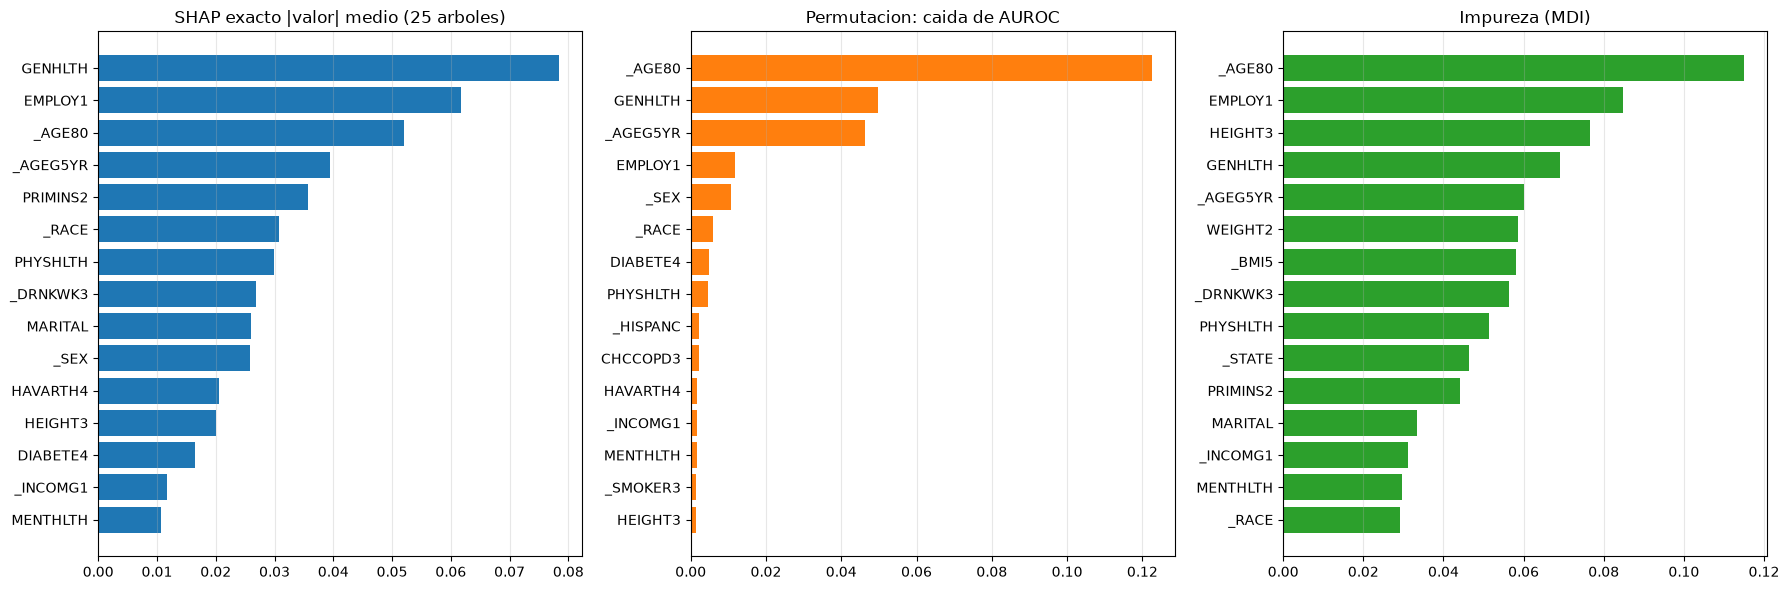

In [23]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 6))
for eje, (col, titulo, color) in zip(ejes, [
    ("shap_exacto_abs", "SHAP exacto |valor| medio (25 arboles)", "tab:blue"),
    ("permutacion_auroc", "Permutacion: caida de AUROC", "tab:orange"),
    ("mdi", "Impureza (MDI)", "tab:green"),
]):
    top = tabla_importancia[col].sort_values(ascending=False).head(15)
    eje.barh(top.index[::-1], top.values[::-1], color=color)
    eje.set(title=titulo)
    eje.grid(alpha=0.3, axis="x")
plt.tight_layout()
guardar_figura(fig, "importancia_variables.png")
plt.show()

C:\Users\seb08\AppData\Local\Temp\ipykernel_25576\2074356048.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_exacto, xai.X_shap_exacto, max_display=15, show=False)


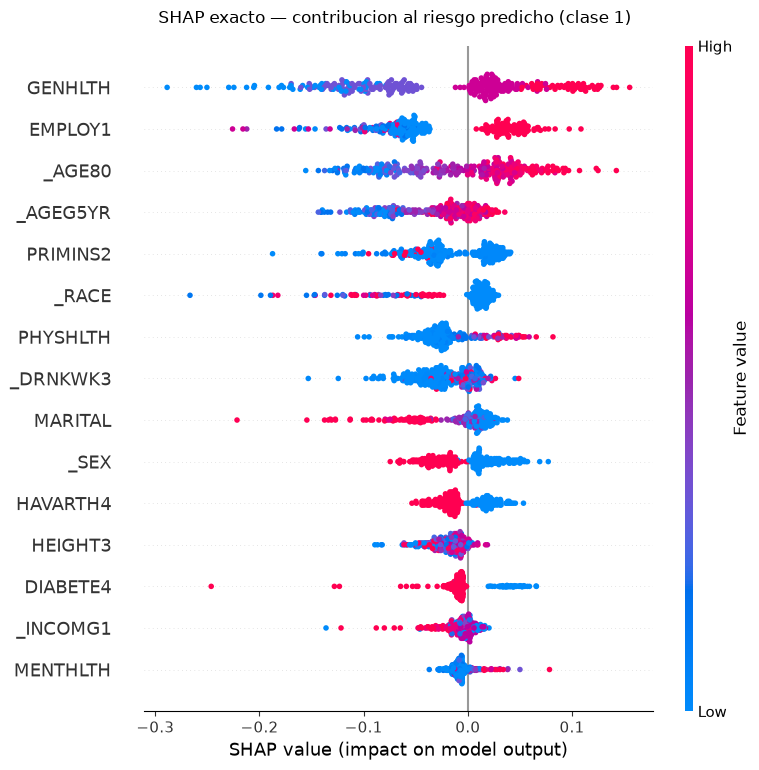

In [24]:
shap.summary_plot(shap_exacto, xai.X_shap_exacto, max_display=15, show=False)
fig = plt.gcf()
fig.suptitle("SHAP exacto — contribucion al riesgo predicho (clase 1)", y=1.02)
guardar_figura(fig, "shap_beeswarm.png")
plt.show()

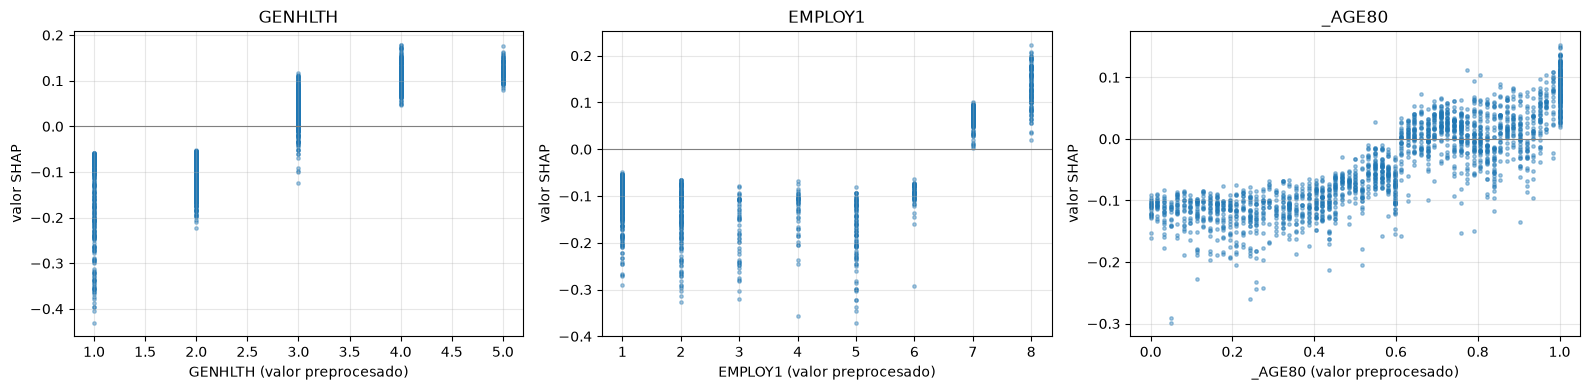

Peso de los atributos protegidos (SHAP exacto abs medio y posicion):
  _SEX: 0.0258 (posicion 10 de 30)
  _RACE: 0.0308 (posicion 6 de 30)
  _INCOMG1: 0.0117 (posicion 14 de 30)


In [25]:
# dependencia SHAP (aproximado, 2000 registros) de las 3 variables mas influyentes
top3 = tabla_importancia.index[:3]
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, var in zip(ejes, top3):
    eje.scatter(xai.X_shap_aprox[var], shap_aprox[:, columnas.index(var)], s=6, alpha=0.4)
    eje.axhline(0, color="gray", lw=0.8)
    eje.set(xlabel=f"{var} (valor preprocesado)", ylabel="valor SHAP", title=var)
    eje.grid(alpha=0.3)
plt.tight_layout()
guardar_figura(fig, "shap_dependencia_top3.png")
plt.show()

print("Peso de los atributos protegidos (SHAP exacto abs medio y posicion):")
for col in pl.PROTECTED_COLS:
    print(f"  {col}: {tabla_importancia.loc[col, 'shap_exacto_abs']:.4f} "
          f"(posicion {tabla_importancia.loc[col, 'rank_shap_exacto_abs']} de {len(columnas)})")

**¿Qué variables dominan?** Las tres vistas coinciden en el núcleo: **`GENHLTH`** (salud percibida), **`EMPLOY1`** (situación laboral) y **la edad** (`_AGE80` y `_AGEG5YR`). Los dos rankings SHAP (exacto y aproximado) son prácticamente iguales (Spearman 0.97), lo que valida usar el bloque de 25 árboles para el SHAP exacto. En el gráfico SHAP la dirección es la esperable: peor salud percibida, mayor edad, ser hombre (`_SEX`=1), tener diabetes (`DIABETE4`=1) o artritis (`HAVARTH4`=1) y más días de mala salud física aumentan el riesgo predicho.

**¿Tiene sentido que dominen?** La edad sí: es el principal factor de riesgo cardiovascular conocido. `GENHLTH` y `EMPLOY1` merecen más cuidado, y son el hallazgo de control de calidad más importante:

1. **Causalidad inversa en la variable objetivo.** El objetivo es haber tenido *alguna vez* un infarto, enfermedad coronaria o ACV (historial), no un evento futuro. `EMPLOY1` empuja el riesgo hacia arriba sobre todo con los códigos 7 (jubilado, un *proxy* de edad) y **8 (incapaz de trabajar)**, y `GENHLTH` alto (salud regular/mala) es el predictor más fuerte. Ambos son plausiblemente **consecuencias** de haber tenido el evento, no causas. No son fuga en sentido estricto (en producción sí estarían disponibles al momento de predecir), pero significan que el modelo en parte **detecta a quien ya tuvo el evento** a través de sus secuelas, en vez de predecir riesgo. Esto debe declararse como limitación en el artículo; una acción concreta es un estudio de ablación sin `GENHLTH`, `EMPLOY1` y `PHYSHLTH` para medir cuánto del AUROC depende de ellas.
2. **Variables redundantes.** `PRIMINS2` (tipo de seguro) es la 5.ª en SHAP pero tiene importancia por permutación ≈0: el modelo la usa, pero al permutarla no pierde nada porque la información está repetida en la edad (Medicare). Lo mismo ocurre con `_AGEG5YR` frente a `_AGE80`, y con `WEIGHT2`/`HEIGHT3` frente a `_BMI5`.
3. **Sesgo de la importancia MDI.** MDI y permutación apenas se correlacionan (Spearman 0.34): MDI infla las variables continuas o con muchos valores (`HEIGHT3` es 3.ª en MDI y 15.ª en permutación; `_DRNKWK3`, `_BMI5`, `WEIGHT2` y `_STATE` tienen MDI alta y permutación nula o negativa). La importancia MDI no debe usarse para conclusiones en este modelo.

**¿Hay alguna que revele un problema en los datos?** No aparece ninguna variable que domine de forma anómala (como lo haría una de las columnas fuente del objetivo, que se excluyeron correctamente en `pipeline.separar_X_y_protegidas`), así que no hay evidencia de fuga directa. Sí es relevante para el análisis de equidad que **`_RACE` sea la 6.ª variable más influyente** en SHAP (y `_SEX` la 10.ª): el modelo usa directamente los atributos protegidos. En el gráfico, el grupo 1 (blanca no hispana) empuja el riesgo hacia arriba y los demás hacia abajo, lo cual es coherente con la menor tasa de positivos predichos (TPR) en los grupos minoritarios y con el EOD por raza de 0.37.

## Análisis de errores

Se usan las predicciones *out-of-fold* de los 5 pliegues (todo el dataset, cada registro predicho por un modelo que no lo vio). Para que el análisis sea interpretable, se recuperan los valores **originales** de cada registro (sin imputar ni normalizar) reconstruyendo los mismos índices de `pipeline.generar_folds()` sobre el CSV original; el orden coincide con el de los archivos `fold_{i}_test.parquet` porque ambos salen de `X.iloc[te_idx].reset_index(drop=True)`.

Cada registro se clasifica en verdadero positivo (VP), falso positivo (FP), verdadero negativo (VN) o falso negativo (FN) al umbral 0.5, y se comparan sus perfiles. También se estudian dos tipos de casos límite: los **ambiguos** (probabilidad entre 0.4 y 0.6) y los **errores con alta confianza** (FP con probabilidad ≥ 0.85 y FN con probabilidad ≤ 0.15).

In [26]:
df_raw = pl.construir_target(pd.read_csv(DATASET_PATH))
X_raw, y_raw, _ = pl.separar_X_y_protegidas(df_raw)
folds_raw = pl.generar_folds(X_raw, y_raw, n_splits=N_PLIEGUES)

partes = []
for i, (_, te_idx) in enumerate(folds_raw):
    parte = X_raw.iloc[te_idx].reset_index(drop=True)
    parte["y_raw"] = y_raw.iloc[te_idx].to_numpy()
    parte["pliegue"] = i
    parte["fila_test"] = np.arange(len(te_idx))
    partes.append(parte)
raw_test = pd.concat(partes, ignore_index=True)

errores = oof.merge(raw_test, on=["pliegue", "fila_test"], how="left")
assert (errores["y"] == errores["y_raw"]).all(), "el orden de los registros no coincide con el cache"

errores["tipo"] = np.select(
    [(errores["y"] == 1) & (errores["pred"] == 1), (errores["y"] == 0) & (errores["pred"] == 1),
     (errores["y"] == 0) & (errores["pred"] == 0)],
    ["VP", "FP", "VN"], default="FN",
)
errores["tipo"].value_counts()

tipo
VN    362230
FN     34923
FP     34355
VP     18252
Name: count, dtype: int64

In [27]:
# Perfil de cada tipo de prediccion con valores originales (NaN = no respondio)
def pct(serie, valor):
    return (serie == valor).mean() * 100

perfil = errores.groupby("tipo").agg(
    n=("y", "size"),
    proba_media=("proba", "mean"),
    edad_media=("_AGE80", "mean"),
    imc_medio=("_BMI5", "mean"),
    dias_salud_fisica_mala=("PHYSHLTH", "mean"),
    pct_hombres=("_SEX", lambda s: pct(s, 1)),
    pct_salud_regular_o_mala=("GENHLTH", lambda s: s.isin([4, 5]).mean() * 100),
    pct_diabetes=("DIABETE4", lambda s: pct(s, 1)),
    pct_renal=("CHCKDNY2", lambda s: pct(s, 1)),
    pct_epoc=("CHCCOPD3", lambda s: pct(s, 1)),
    pct_no_puede_trabajar=("EMPLOY1", lambda s: pct(s, 8)),
    pct_ingreso_faltante=("_INCOMG1", lambda s: s.isna().mean() * 100),
).loc[["VP", "FN", "FP", "VN"]]
perfil.round(2)

,n,proba_media,edad_media,imc_medio,dias_salud_fisica_mala,pct_hombres,pct_salud_regular_o_mala,pct_diabetes,pct_renal,pct_epoc,pct_no_puede_trabajar,pct_ingreso_faltante
tipo,,,,,,,,,,,,
VP,18252,0.65,72.00,29.26,14.02,62.03,66.75,43.51,20.79,30.56,21.15,16.84
FN,34923,0.30,65.58,29.10,6.63,50.49,31.24,25.87,11.65,16.65,10.43,19.96
FP,34355,0.63,70.94,29.10,10.86,55.58,50.32,31.83,10.82,19.00,17.85,18.45
VN,362230,0.16,51.55,28.40,3.27,45.62,12.76,9.90,3.11,4.80,3.53,18.88


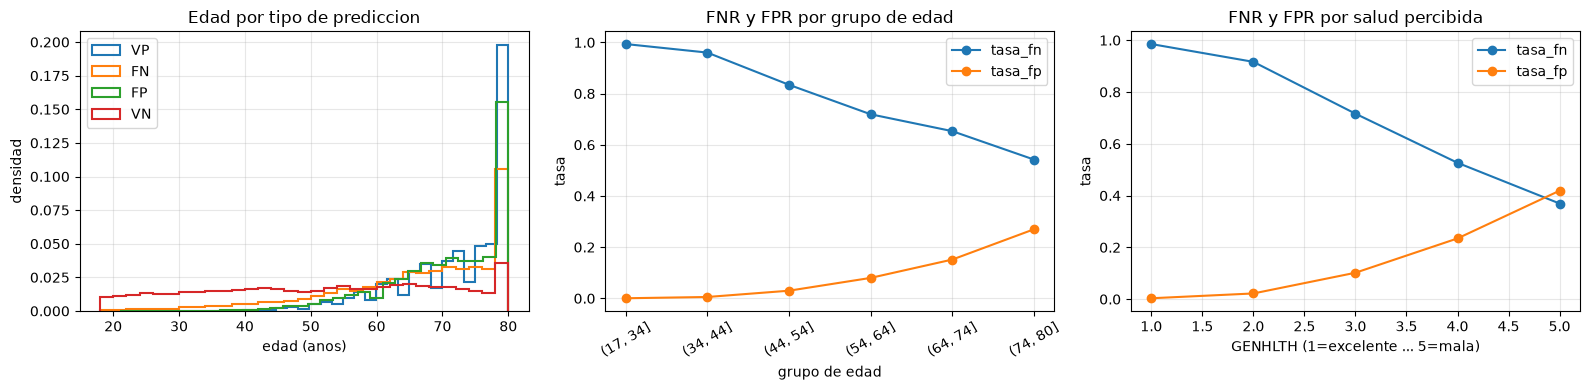

,tasa_fn,tasa_fp
grupo_edad,,
"(17, 34]",0.994,0.000
"(34, 44]",0.960,0.005
"(44, 54]",0.834,0.030
"(54, 64]",0.719,0.080
"(64, 74]",0.653,0.152
"(74, 80]",0.542,0.270


In [28]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for tipo in ["VP", "FN", "FP", "VN"]:
    sub = errores[errores["tipo"] == tipo]
    ejes[0].hist(sub["_AGE80"], bins=31, histtype="step", density=True, lw=1.5, label=tipo)
ejes[0].set(xlabel="edad (anos)", ylabel="densidad", title="Edad por tipo de prediccion")
ejes[0].legend()

tasa_error_edad = errores.assign(grupo_edad=pd.cut(errores["_AGE80"], bins=[17, 34, 44, 54, 64, 74, 80])).groupby("grupo_edad", observed=True).agg(
    tasa_fn=("tipo", lambda s: (s == "FN").sum() / max(((s == "FN") | (s == "VP")).sum(), 1)),
    tasa_fp=("tipo", lambda s: (s == "FP").sum() / max(((s == "FP") | (s == "VN")).sum(), 1)),
)
tasa_error_edad.plot(ax=ejes[1], marker="o")
ejes[1].set(xlabel="grupo de edad", ylabel="tasa", title="FNR y FPR por grupo de edad")
ejes[1].tick_params(axis="x", rotation=30)

salud = errores.groupby("GENHLTH").agg(
    tasa_fn=("tipo", lambda s: (s == "FN").sum() / max(((s == "FN") | (s == "VP")).sum(), 1)),
    tasa_fp=("tipo", lambda s: (s == "FP").sum() / max(((s == "FP") | (s == "VN")).sum(), 1)),
)
salud.plot(ax=ejes[2], marker="o")
ejes[2].set(xlabel="GENHLTH (1=excelente ... 5=mala)", ylabel="tasa", title="FNR y FPR por salud percibida")
for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
guardar_figura(fig, "analisis_errores.png")
plt.show()
tasa_error_edad.round(3)

In [29]:
# Casos limite
ambiguos = errores[errores["proba"].between(0.4, 0.6)]
fp_confiados = errores[(errores["tipo"] == "FP") & (errores["proba"] >= 0.85)]
fn_confiados = errores[(errores["tipo"] == "FN") & (errores["proba"] <= 0.15)]

print(f"ambiguos (0.4 <= p <= 0.6): {len(ambiguos):,} registros ({len(ambiguos) / len(errores):.1%}), "
      f"tasa real de positivos {ambiguos['y'].mean():.1%}")
print(f"FP con p >= 0.85: {len(fp_confiados):,} | FN con p <= 0.15: {len(fn_confiados):,} "
      f"({len(fn_confiados) / (errores['y'] == 1).sum():.1%} de todos los positivos)")

columnas_caso = ["proba", "y", "_AGE80", "_SEX", "_RACE", "_INCOMG1", "GENHLTH", "PHYSHLTH", "DIABETE4",
                 "CHCKDNY2", "CHCCOPD3", "HAVARTH4", "_SMOKER3", "EMPLOY1", "_BMI5"]
print("\nEjemplos de FN muy confiados (el modelo los ve como de bajo riesgo):")
display(fn_confiados.sort_values("proba")[columnas_caso].head(8))
print("Ejemplos de FP muy confiados (el modelo los ve como de alto riesgo):")
display(fp_confiados.sort_values("proba", ascending=False)[columnas_caso].head(8))

ambiguos (0.4 <= p <= 0.6): 61,572 registros (13.7%), tasa real de positivos 27.5%
FP con p >= 0.85: 1,059 | FN con p <= 0.15: 5,077 (9.5% de todos los positivos)

Ejemplos de FN muy confiados (el modelo los ve como de bajo riesgo):


,proba,y,_AGE80,_SEX,_RACE,_INCOMG1,GENHLTH,PHYSHLTH,DIABETE4,CHCKDNY2,CHCCOPD3,HAVARTH4,_SMOKER3,EMPLOY1,_BMI5
74490,0.0,1,43.0,1.0,1.0,6.0,1.0,0.0,3.0,2.0,2.0,2.0,4.0,1.0,27.26
432739,0.0,1,20.0,1.0,2.0,6.0,2.0,0.0,3.0,2.0,2.0,2.0,4.0,6.0,27.20
388273,0.0,1,22.0,1.0,1.0,7.0,1.0,0.0,3.0,2.0,2.0,2.0,4.0,1.0,23.75
109166,0.0,1,26.0,2.0,1.0,5.0,2.0,0.0,3.0,2.0,2.0,2.0,4.0,1.0,26.45
427905,0.0,1,25.0,1.0,1.0,7.0,1.0,0.0,3.0,2.0,2.0,2.0,4.0,1.0,26.50
426309,0.0,1,38.0,1.0,7.0,6.0,1.0,0.0,3.0,2.0,2.0,2.0,4.0,1.0,25.09
81673,0.0,1,46.0,1.0,1.0,6.0,1.0,0.0,3.0,2.0,2.0,2.0,4.0,1.0,29.05
251798,0.0,1,28.0,2.0,8.0,3.0,2.0,0.0,3.0,2.0,2.0,2.0,4.0,3.0,37.11


Ejemplos de FP muy confiados (el modelo los ve como de alto riesgo):


,proba,y,_AGE80,_SEX,_RACE,_INCOMG1,GENHLTH,PHYSHLTH,DIABETE4,CHCKDNY2,CHCCOPD3,HAVARTH4,_SMOKER3,EMPLOY1,_BMI5
200013,0.976667,0,74.0,1.0,1.0,5.0,5.0,30.0,1.0,1.0,1.0,1.0,3.0,7.0,33.96
291111,0.970000,0,80.0,1.0,1.0,5.0,2.0,0.0,3.0,2.0,2.0,2.0,3.0,7.0,28.48
216158,0.970000,0,80.0,1.0,1.0,5.0,4.0,30.0,1.0,2.0,2.0,2.0,3.0,7.0,25.54
227787,0.970000,0,80.0,1.0,1.0,5.0,4.0,5.0,1.0,2.0,2.0,1.0,3.0,7.0,27.89
273633,0.970000,0,80.0,2.0,1.0,4.0,4.0,20.0,3.0,2.0,2.0,1.0,NaN,7.0,NaN
229955,0.970000,0,68.0,1.0,1.0,2.0,5.0,30.0,3.0,2.0,1.0,1.0,3.0,8.0,27.26
426950,0.966667,0,62.0,2.0,1.0,2.0,5.0,30.0,1.0,1.0,2.0,1.0,3.0,8.0,33.09
375260,0.966667,0,63.0,2.0,1.0,2.0,5.0,30.0,3.0,2.0,1.0,1.0,1.0,8.0,20.47


In [30]:
# Perfil de los FN confiados frente a los VP: que les falta para que el modelo los detecte
comparar = pd.DataFrame({
    "VP": errores[errores["tipo"] == "VP"][["_AGE80", "PHYSHLTH", "_BMI5"]].mean(),
    "FN confiados": fn_confiados[["_AGE80", "PHYSHLTH", "_BMI5"]].mean(),
    "FP confiados": fp_confiados[["_AGE80", "PHYSHLTH", "_BMI5"]].mean(),
    "VN": errores[errores["tipo"] == "VN"][["_AGE80", "PHYSHLTH", "_BMI5"]].mean(),
})
for etiqueta, condicion in {"% salud regular/mala": lambda d: d["GENHLTH"].isin([4, 5]).mean() * 100,
                            "% diabetes": lambda d: (d["DIABETE4"] == 1).mean() * 100,
                            "% hombres": lambda d: (d["_SEX"] == 1).mean() * 100}.items():
    comparar.loc[etiqueta] = [condicion(errores[errores["tipo"] == "VP"]), condicion(fn_confiados),
                              condicion(fp_confiados), condicion(errores[errores["tipo"] == "VN"])]
comparar.round(2)

,VP,FN confiados,FP confiados,VN
_AGE80,72.00,52.34,72.18,51.55
PHYSHLTH,14.02,2.32,21.58,3.27
_BMI5,29.26,28.34,29.27,28.40
% salud regular/mala,66.75,7.82,86.87,12.76
% diabetes,43.51,7.35,40.79,9.90
% hombres,62.03,43.55,65.06,45.62


**Falsos negativos (34 923, el 66 % de los positivos).** Son, en promedio, más jóvenes que los verdaderos positivos (65.6 vs. 72.0 años), reportan mejor salud (31 % con salud regular/mala vs. 67 %), menos días de mala salud física (6.6 vs. 14.0) y menos comorbilidades (diabetes 26 % vs. 44 %; enfermedad renal 12 % vs. 21 %). La tasa de FN depende fuertemente de la edad: 99 % por debajo de 35 años, 83 % entre 45 y 54, y 54 % entre 75 y 80. Los **FN con alta confianza** (p ≤ 0.15, 5 077 registros, 9.5 % de los positivos) son personas jóvenes, sin comorbilidades, con excelente salud percibida y empleadas: el modelo no tiene ninguna señal para detectarlos. Parte de ellos pueden ser **ruido en la etiqueta** propio de una encuesta autorreportada (por ejemplo, un "infarto" reportado a los 20 años sin ningún otro factor), y parte son eventos que no se explican con las variables disponibles.

**Falsos positivos (34 355).** Su perfil es casi idéntico al de los verdaderos positivos (edad 70.9 vs. 72.0, 50 % con salud regular/mala, 32 % con diabetes). Los **FP con alta confianza** (p ≥ 0.85, 1 059) son personas de 62 a 80 años, jubiladas o incapaces de trabajar, con salud mala y 20–30 días de mala salud física, a menudo con diabetes o EPOC. Clínicamente son pacientes de alto riesgo real; que no hayan tenido (o no hayan reportado) un evento no los hace errores graves para un uso de tamizaje.

**Casos límite.** El 13.7 % de los registros cae en la zona ambigua (0.4 ≤ p ≤ 0.6) y su tasa real de positivos es 27.5 %, más del doble de la prevalencia, pero lejos de 50 %: es otra manifestación de la sobreestimación de probabilidades por entrenar con datos balanceados.

**Conclusión del análisis de errores.** El modelo funciona como un detector de "perfil de paciente mayor y enfermo": acierta cuando el evento viene acompañado de edad y comorbilidades y falla de forma sistemática con los positivos jóvenes y sanos. Esto es coherente con la importancia de `GENHLTH`, `EMPLOY1` y la edad en SHAP, y sugiere que el desempeño está limitado por la información de las variables más que por el modelo (de ahí también la curva de aprendizaje plana).

In [31]:
del xai, acumulador, df_raw, X_raw, raw_test
gc.collect();

## Comparación exploratoria: SMOTENC vs. class weighting

Esta sección es exploratoria y no forma parte del resultado principal. Igual que en el cuaderno de XGBoost, se repite el ciclo de 5 pliegues con los mismos hiperparámetros, pero sustituyendo SMOTENC por `class_weight="balanced"` (entrenando con el train sin SMOTENC), para observar si una alternativa que no genera datos sintéticos produce resultados de equidad distintos.

In [32]:
resultados_cw = []

for i in range(N_PLIEGUES):
    X_train, y_train = cargar(f"fold_{i}_train_sin_smotenc.parquet")
    X_test, y_test = cargar(f"fold_{i}_test.parquet")
    prot_test = X_test[pl.PROTECTED_COLS]

    # class_weight="balanced" depende solo de y_train, asi que es identico en todos los bloques
    y_proba = bosque_por_bloques({**MEJORES_HIPERPARAMETROS, "class_weight": "balanced"},
                                 X_train, y_train, {"test": X_test})["test"]
    y_pred = (y_proba > 0.5).astype(int)

    resumen_cw, _ = pl.evaluar(y_test, y_pred, y_proba, prot_test)
    resumen_cw["modelo"] = "random_forest_class_weight"
    resumen_cw["pliegue"] = i
    resultados_cw.append(resumen_cw)
    print(f"pliegue {i} listo | AUROC = {resumen_cw['auroc']:.4f}")

pliegue 0 listo | AUROC = 0.8202


pliegue 1 listo | AUROC = 0.8196


pliegue 2 listo | AUROC = 0.8222


pliegue 3 listo | AUROC = 0.8187


pliegue 4 listo | AUROC = 0.8206


In [33]:
tabla_cw = pd.DataFrame(resultados_cw)
tabla_cw = tabla_cw[columnas_ordenadas]

tabla_cw.to_csv(f"{RESULTS_DIR}/metrics_random_forest_class_weight.csv", index=False)
print("guardado en results/metrics_random_forest_class_weight.csv")

comparacion = pd.DataFrame({
    "smotenc": tabla_metricas.drop(columns=["modelo", "pliegue"]).mean(),
    "class_weight": tabla_cw.drop(columns=["modelo", "pliegue"]).mean(),
}).round(4)
comparacion

guardado en results/metrics_random_forest_class_weight.csv


,smotenc,class_weight
auroc,0.7965,0.8203
eod_sexo,0.1049,0.1352
fpr_disp_sexo,0.0317,0.0373
calib_desv_sexo,1.0940,0.8110
eod_raza,0.3736,0.2417
fpr_disp_raza,0.1123,0.0612
calib_desv_raza,1.1400,1.2374
eod_ingreso,0.2579,0.2760
fpr_disp_ingreso,0.1186,0.1043
calib_desv_ingreso,1.2988,0.8761


**Resultado.** A diferencia de XGBoost, en el Random Forest **`class_weight="balanced"` mejora a SMOTENC en casi todo**:

- **AUROC**: 0.8203 vs. 0.7965 (+0.024), y supera incluso a XGBoost con SMOTENC (0.8071).
- **Equidad por raza**: EOD 0.242 vs. 0.374 y disparidad de FPR 0.061 vs. 0.112. En sexo e ingreso el EOD empeora levemente (0.135 vs. 0.105 y 0.276 vs. 0.258).
- **Calibración**: mejora en sexo e ingreso (0.81 y 0.88 vs. 1.09 y 1.30) y empeora un poco en raza (1.24 vs. 1.14).

En XGBoost, `scale_pos_weight` disparaba la desviación de calibración (de 0.36 a 2.51 en raza); en el Random Forest no ocurre. Una explicación plausible es el mecanismo de cada modelo: en XGBoost el peso multiplica directamente el gradiente de la pérdida e infla las probabilidades de forma uniforme, mientras que en el Random Forest con hojas puras (`min_samples_leaf=1`) el peso solo cambia **dónde** se hacen las divisiones; la probabilidad final sigue siendo la fracción de árboles que votan por la clase 1, entrenados sobre datos **reales** con la prevalencia verdadera. SMOTENC, en cambio, introduce ≈275 000 registros sintéticos por pliegue que el bosque memoriza (AUROC de train = 1.0), y sus hojas sintéticas desplazan las probabilidades hacia arriba.

Esto **no cambia** el resultado principal reportado arriba (que usa SMOTENC para mantener el mismo protocolo en los cuatro modelos), pero sí es un hallazgo relevante para el artículo: la conveniencia de SMOTENC frente a *class weighting* **depende del modelo**, y para el Random Forest la alternativa sin datos sintéticos es mejor en discriminación y en la equidad por raza.

**Nota de costo:** esta sección tardó ≈55 minutos (frente a ≈6 minutos por pliegue con SMOTENC), porque con pesos balanceados los árboles completos siguen dividiendo mucho más para aislar los positivos ponderados.

## Conclusiones

1. **Discriminación**: AUROC 0.7965 ± 0.0008 con SMOTENC. Supera el baseline de literatura (0.751–0.771) y el baseline trivial (0.50), pero solo mejora en 0.010 a una regresión logística sin ajuste (0.786) y queda 0.011 por debajo de XGBoost (0.807).
2. **Equidad**: EOD por sexo 0.105 (por debajo del rango de literatura, 0.131–0.136), pero disparidad alta por raza (EOD 0.37) e ingreso (0.26), peor que XGBoost y mejor que la LR baseline en raza. `_RACE` es la 6.ª variable más influyente del modelo.
3. **Sobreajuste**: memorización total del train (AUROC 1.0), esperada con árboles completos; la generalización es estable y la curva de aprendizaje indica que el límite está en la información de las variables, no en la cantidad de datos.
4. **Explicabilidad (control de calidad)**: dominan `GENHLTH`, `EMPLOY1` y la edad. Las dos primeras probablemente reflejan secuelas del evento (el objetivo es un historial, no un evento futuro): no es fuga en sentido estricto, pero es una limitación a declarar. Se recomienda un estudio de ablación sin estas variables.
5. **Errores**: el modelo falla sistemáticamente con los positivos jóvenes y sin comorbilidades (99 % de FN por debajo de 35 años) y sus falsos positivos más confiados tienen el mismo perfil clínico que los verdaderos positivos.
6. **SMOTENC vs. class weighting**: en el Random Forest, `class_weight="balanced"` mejora el AUROC (0.820) y la equidad por raza sin el deterioro de calibración observado en XGBoost. La técnica de balanceo óptima depende del modelo.